# Лабораторна робота 3

**Тема:**
Розробити програмний засіб, який здійснює афінне перетворення множини точок заданих своїми координатами та відображує її на координатній площині і зберігає зображення в одному з графічних форматів.

**Виконав:** Бугайчук Василь 

**Група:** КМ-51

 

# Хід роботи

- Вивчити математичні основи афінних перетворень і особливості їх реалізації

- Використати датасет з лабораторної роботи №2

- Визначити афінне перетворенняяк обертання навколо точки (480; 480) на кут

- α = 10° × (n + 1), де n — остання цифра логіну на платформі Сікорський.

 і розрахувати його результуючу матрицю

- Скачати файл з датасетом. Файл в текстовому форматі містить пари цілих чисел які є координатами точок. 

# Необхідно написати програму будь якою мовою з використанням будь яких бібліотек яка

1. Зчитує датасет з файлу;
2. Виконує задане афінне перетворення з датасетом;
3. Встановлює розміри вікна (полотна – canvas size) 960х960 пкс;
4. Відображає  датасет після афінного перетворення точками синього кольору;
5. Виводить результати у файли будь-якого графічного формату

Кут обертання: 80°. Матриця афінного перетворення:
    0.173648    -0.984808   869.356596
    0.984808     0.173648   -76.058847
    0.000000     0.000000     1.000000
Збережено 48802 точок у transformed_DS7.txt.
Збережено transformed_result.png (960 × 960 пкс).


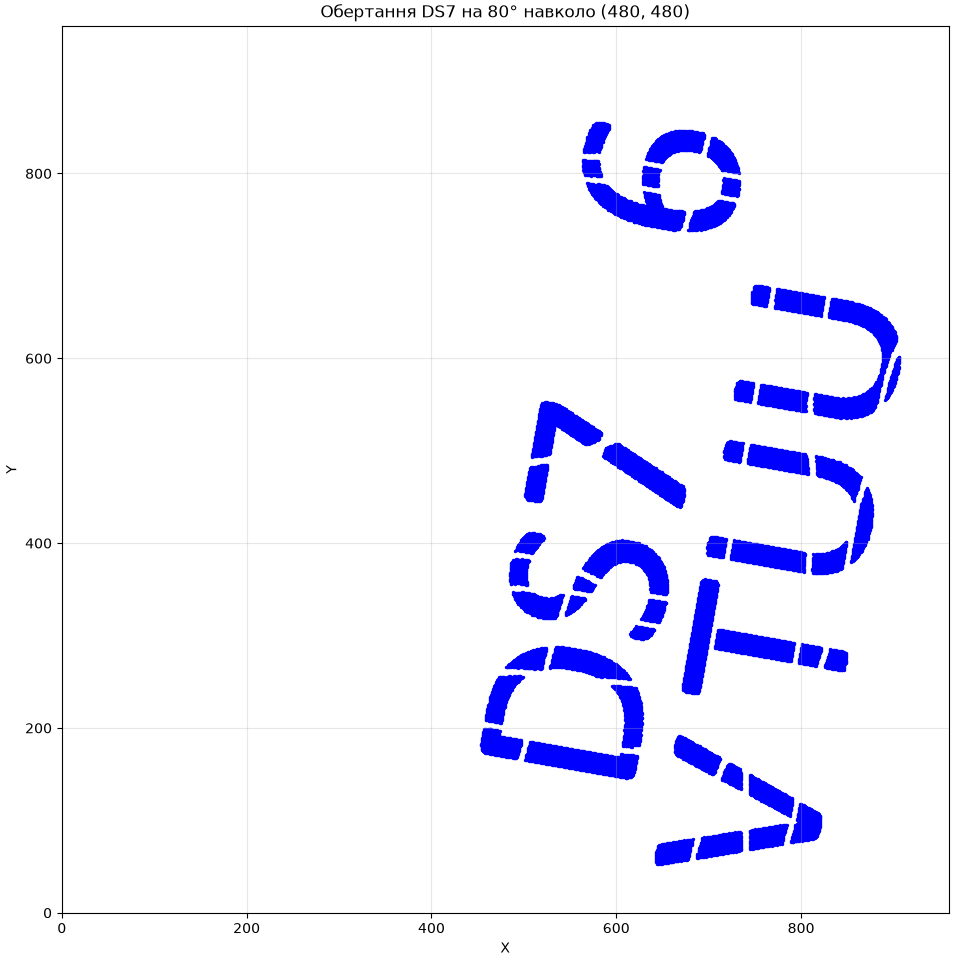

In [2]:
from pathlib import Path
import math
import matplotlib.pyplot as plt

# Підтримуємо запуск із папки лабораторної або кореня репозиторію.
root = Path.cwd()
if not (root / "лабораторна робота 2").is_dir():
    root = root.parent

input_path = root / "лабораторна робота 2" / "DS7.txt"
output_dir = root / "лабораторна робота 3"
points = []
with input_path.open(encoding="utf-8") as file:
    for line in file:
        if line.strip() and not line.lstrip().startswith("#"):
            x, y = map(float, line.split())
            points.append((x, y))

# DS7 відповідає варіанту 7. Якщо цифра логіну інша, змініть n.
n = 7
angle_deg = 10 * (n + 1)
angle_rad = math.radians(angle_deg)
cos_a, sin_a = math.cos(angle_rad), math.sin(angle_rad)
xp, yp = 480.0, 480.0

# Однорідні координати, вектор-стовпець: T(P) @ R(alpha) @ T(-P).
rotation_matrix = [
    [cos_a, -sin_a, xp - xp * cos_a + yp * sin_a],
    [sin_a, cos_a, yp - xp * sin_a - yp * cos_a],
    [0.0, 0.0, 1.0],
]
print(f"Кут обертання: {angle_deg}°. Матриця афінного перетворення:")
for row in rotation_matrix:
    print(" ".join(f"{value:12.6f}" for value in row))

transformed_points = []
for x, y in points:
    new_x = rotation_matrix[0][0] * x + rotation_matrix[0][1] * y + rotation_matrix[0][2]
    new_y = rotation_matrix[1][0] * x + rotation_matrix[1][1] * y + rotation_matrix[1][2]
    transformed_points.append((new_x, new_y))

# Передаємо повний результат, включно з точками поза початковими межами, у № 4.
data_path = output_dir / "transformed_DS7.txt"
with data_path.open("w", encoding="utf-8") as file:
    file.write(f"# DS7; n={n}; angle={angle_deg}; pivot=480,480\n")
    for x, y in transformed_points:
        file.write(f"{x:.12f} {y:.12f}\n")

xs = [x for x, y in transformed_points]
ys = [y for x, y in transformed_points]
fig, ax = plt.subplots(figsize=(9.6, 9.6), dpi=100, layout="constrained")
ax.scatter(xs, ys, color="blue", s=2)
# Розмір полотна в пікселях і межі координат задаються незалежно.
ax.set_xlim(min(0, min(xs) - 20), max(960, max(xs) + 20))
ax.set_ylim(min(0, min(ys) - 20), max(960, max(ys) + 20))
ax.set_aspect("equal", adjustable="box")
ax.set(xlabel="X", ylabel="Y",
       title=f"Обертання DS7 на {angle_deg}° навколо (480, 480)")
ax.grid(True, alpha=0.3)
fig.savefig(output_dir / "transformed_result.png", dpi=100)
plt.show()
print(f"Збережено {len(transformed_points)} точок у {data_path.name}.")
print("Збережено transformed_result.png (960 × 960 пкс).")
